In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

classification_df = pd.read_csv(
    "../Data/processed/classification_clean.csv"
)

regression_df = pd.read_csv(
    "../Data/processed/regression_clean.csv"
)

print(classification_df.shape)
print(regression_df.shape)


(938599, 24)
(136209, 28)


In [2]:
classification_df.head()

,pha,H,diameter,albedo,epoch,epoch_mjd,epoch_cal,e,a,q,...,tp_cal,per,per_y,rms,om_sin,om_cos,w_sin,w_cos,ma_sin,ma_cos
0,N,3.40,939.400,0.0900,2458600.5,58600,20190427.0,0.076009,2.769165,2.558684,...,2.018043e+07,1683.145703,4.608202,0.43301,0.985720,0.168394,0.959303,0.282380,0.975810,0.218618
1,N,4.20,545.000,0.1010,2459000.5,59000,20200531.0,0.229972,2.773841,2.135935,...,2.018072e+07,1687.410992,4.619880,0.35936,0.121441,-0.992599,-0.763769,0.645490,0.573924,-0.818908
2,N,5.33,246.596,0.2140,2459000.5,59000,20200531.0,0.256936,2.668285,1.982706,...,2.018112e+07,1592.013769,4.358696,0.33848,0.176200,-0.984354,-0.927616,-0.373535,0.814770,-0.579784
3,N,3.00,525.400,0.4228,2458600.5,58600,20190427.0,0.088721,2.361418,2.151909,...,2.018051e+07,1325.432763,3.628837,0.39980,0.971089,-0.238717,0.488948,-0.872313,0.994771,-0.102132
4,N,6.90,106.699,0.2740,2459000.5,59000,20200531.0,0.190913,2.574037,2.082619,...,2.020032e+07,1508.414421,4.129814,0.52191,0.621544,-0.783379,-0.023587,0.999722,0.306465,0.951882


In [3]:
regression_df.head()

,neo,pha,H,diameter,albedo,epoch,epoch_mjd,epoch_cal,e,a,...,moid,moid_ld,class,rms,om_sin,om_cos,w_sin,w_cos,ma_sin,ma_cos
0,N,N,3.40,939.400,0.0900,2458600.5,58600,20190427.0,0.076009,2.769165,...,1.59478,620.640533,MBA,0.43301,0.985720,0.168394,0.959303,0.282380,0.975810,0.218618
1,N,N,4.20,545.000,0.1010,2459000.5,59000,20200531.0,0.229972,2.773841,...,1.23429,480.348639,MBA,0.35936,0.121441,-0.992599,-0.763769,0.645490,0.573924,-0.818908
2,N,N,5.33,246.596,0.2140,2459000.5,59000,20200531.0,0.256936,2.668285,...,1.03429,402.514639,MBA,0.33848,0.176200,-0.984354,-0.927616,-0.373535,0.814770,-0.579784
3,N,N,3.00,525.400,0.4228,2458600.5,58600,20190427.0,0.088721,2.361418,...,1.13948,443.451432,MBA,0.39980,0.971089,-0.238717,0.488948,-0.872313,0.994771,-0.102132
4,N,N,6.90,106.699,0.2740,2459000.5,59000,20200531.0,0.190913,2.574037,...,1.09575,426.433027,MBA,0.52191,0.621544,-0.783379,-0.023587,0.999722,0.306465,0.951882


In [4]:
classification_df['pha'].value_counts()

pha
N    936533
Y      2066
Name: count, dtype: int64

In [5]:
classification_df['pha'].value_counts(normalize=True)*100

pha
N    99.779885
Y     0.220115
Name: proportion, dtype: float64

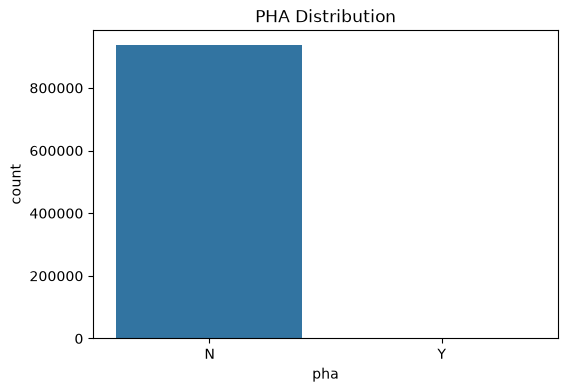

In [6]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=classification_df,
    x='pha'
)

plt.title("PHA Distribution")

plt.show()

In [9]:
regression_df['diameter'].value_counts()

diameter
4.017    45
3.296    45
3.008    44
3.122    44
3.377    44
         ..
0.404     1
0.587     1
0.122     1
0.651     1
1.077     1
Name: count, Length: 16591, dtype: int64

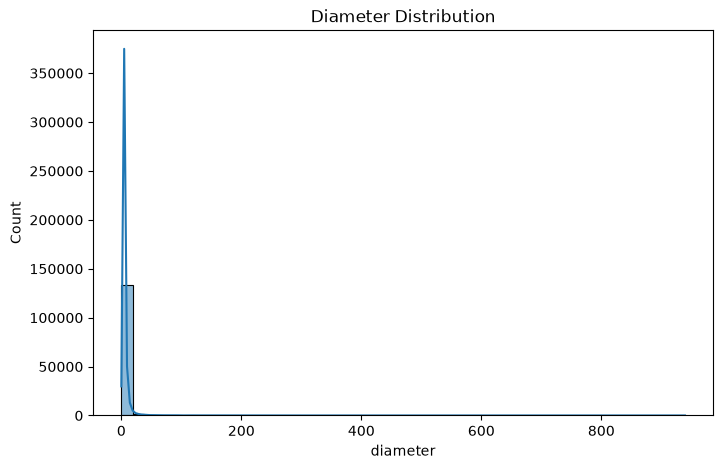

In [7]:
plt.figure(figsize=(8,5))

sns.histplot(
    regression_df['diameter'],
    bins=50,
    kde=True
)

plt.title("Diameter Distribution")
plt.show()

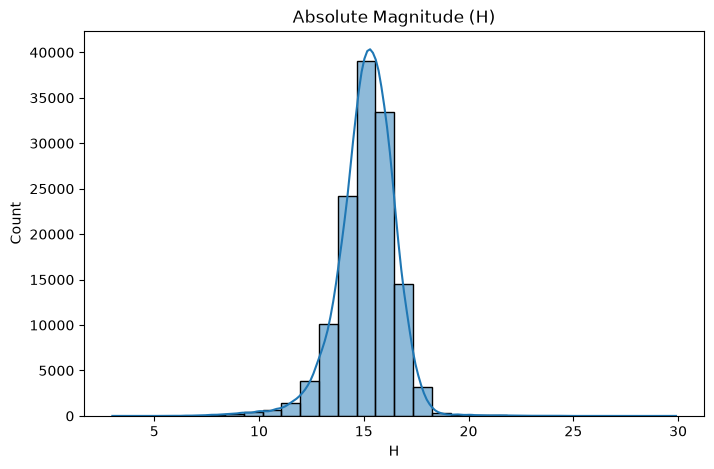

In [10]:
plt.figure(figsize=(8,5))

sns.histplot(
    regression_df['H'],
    bins=30,
    kde=True
)

plt.title("Absolute Magnitude (H)")
plt.show()

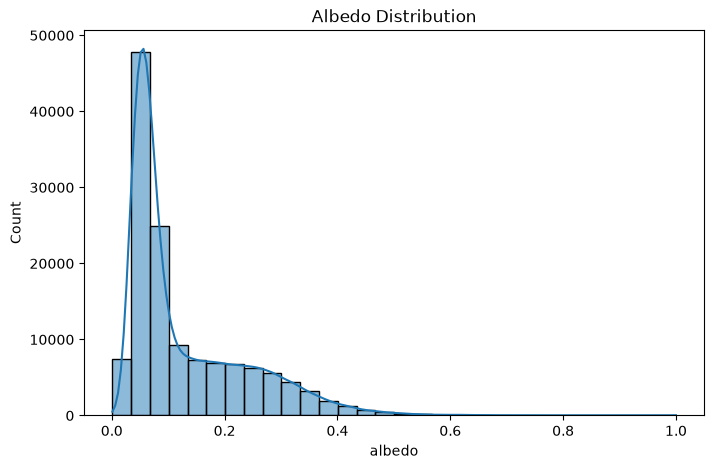

In [11]:
plt.figure(figsize=(8,5))

sns.histplot(
    regression_df['albedo'],
    bins=30,
    kde=True
)

plt.title("Albedo Distribution")

plt.show()

In [12]:
regression_df.describe().T

,count,mean,std,min,25%,50%,75%,max
H,132045.0,1.513232e+01,1.387944,3.000000e+00,1.440000e+01,1.520000e+01,1.600000e+01,2.990000e+01
diameter,136209.0,5.506429e+00,9.425164,2.500000e-03,2.780000e+00,3.972000e+00,5.765000e+00,9.394000e+02
albedo,135100.0,1.306254e-01,0.110323,1.000000e-03,5.300000e-02,7.900000e-02,1.900000e-01,1.000000e+00
epoch,136209.0,2.458882e+06,648.426065,2.452464e+06,2.459000e+06,2.459000e+06,2.459000e+06,2.459000e+06
epoch_mjd,136209.0,5.888193e+04,648.426065,5.246400e+04,5.900000e+04,5.900000e+04,5.900000e+04,5.900000e+04
epoch_cal,136209.0,2.019732e+07,17633.835654,2.002071e+07,2.020053e+07,2.020053e+07,2.020053e+07,2.020053e+07
e,136209.0,1.456603e-01,0.077464,6.025354e-05,8.987830e-02,1.389189e-01,1.911743e-01,9.837890e-01
a,136209.0,2.819158e+00,1.495980,6.262100e-01,2.542856e+00,2.754950e+00,3.095029e+00,3.761333e+02
q,136209.0,2.406130e+00,0.516931,8.181996e-02,2.072478e+00,2.368605e+00,2.688275e+00,4.031848e+01
i,136209.0,1.029536e+01,6.812632,2.205649e-02,5.088142e+00,9.335690e+00,1.367033e+01,1.703346e+02


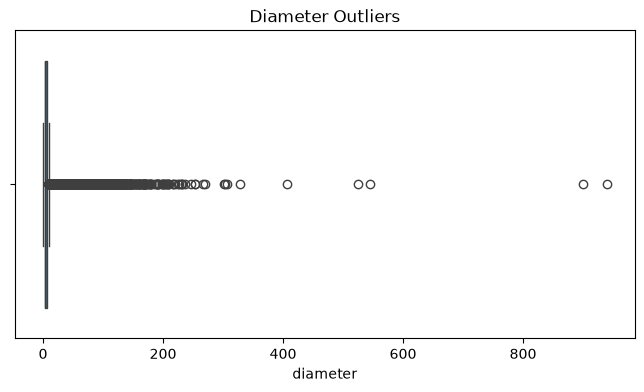

In [13]:
plt.figure(figsize=(8,4))

sns.boxplot(
    x=regression_df['diameter']
)

plt.title(
    "Diameter Outliers"
)

plt.show()

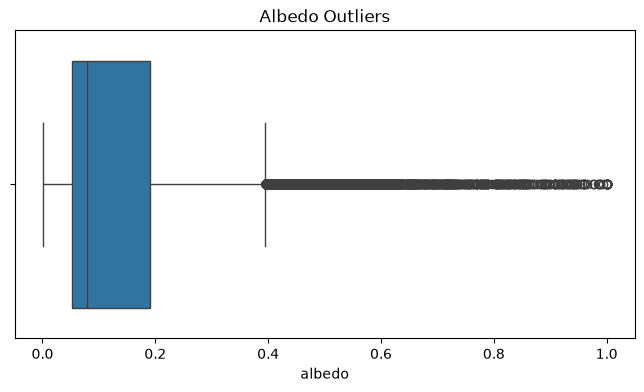

In [14]:
plt.figure(figsize=(8,4))

sns.boxplot(
    x=regression_df['albedo']
)

plt.title(
    "Albedo Outliers"
)

plt.show()

In [15]:
numeric_cols = regression_df.select_dtypes(
    include=np.number
).columns

regression_df[numeric_cols]\
    .skew()\
    .sort_values(
        ascending=False
    )

per_y        249.879621
per          249.879621
ad           199.089250
a            174.781076
diameter      25.852418
rms            8.741995
moid           7.601012
moid_ld        7.601012
q              7.314837
n              6.026977
albedo         1.683626
i              1.659299
e              1.407371
ma_sin         0.069253
w_sin          0.031020
om_cos         0.021613
w_cos          0.003547
ma_cos        -0.066954
om_sin        -0.195418
H             -0.687398
tp_cal        -3.099067
tp            -3.168572
epoch_cal     -5.315703
epoch_mjd     -5.317796
epoch         -5.317796
dtype: float64

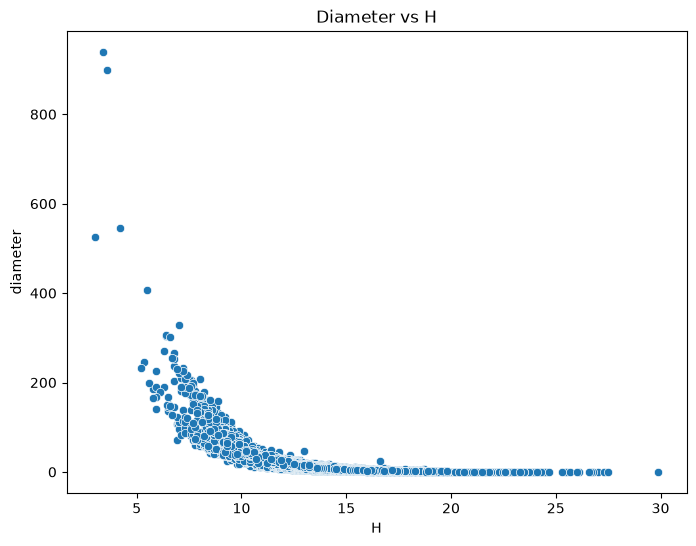

In [16]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=regression_df,
    x='H',
    y='diameter'
)

plt.title(
    "Diameter vs H"
)

plt.show()

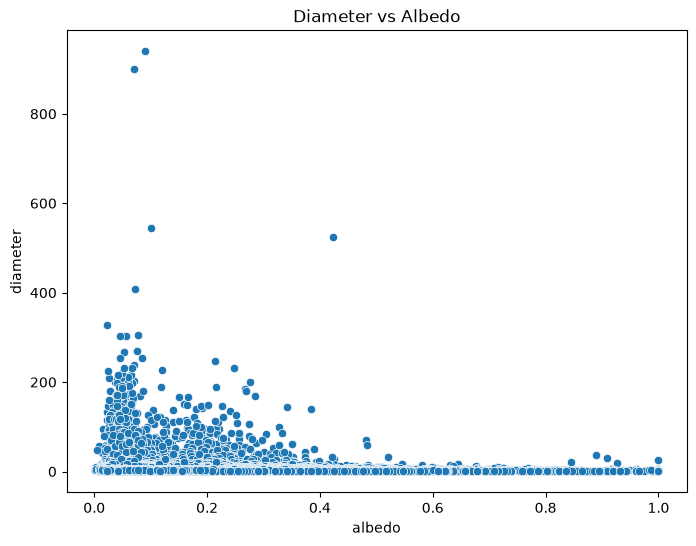

In [17]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=regression_df,
    x='albedo',
    y='diameter'
)

plt.title(
    "Diameter vs Albedo"
)

plt.show()

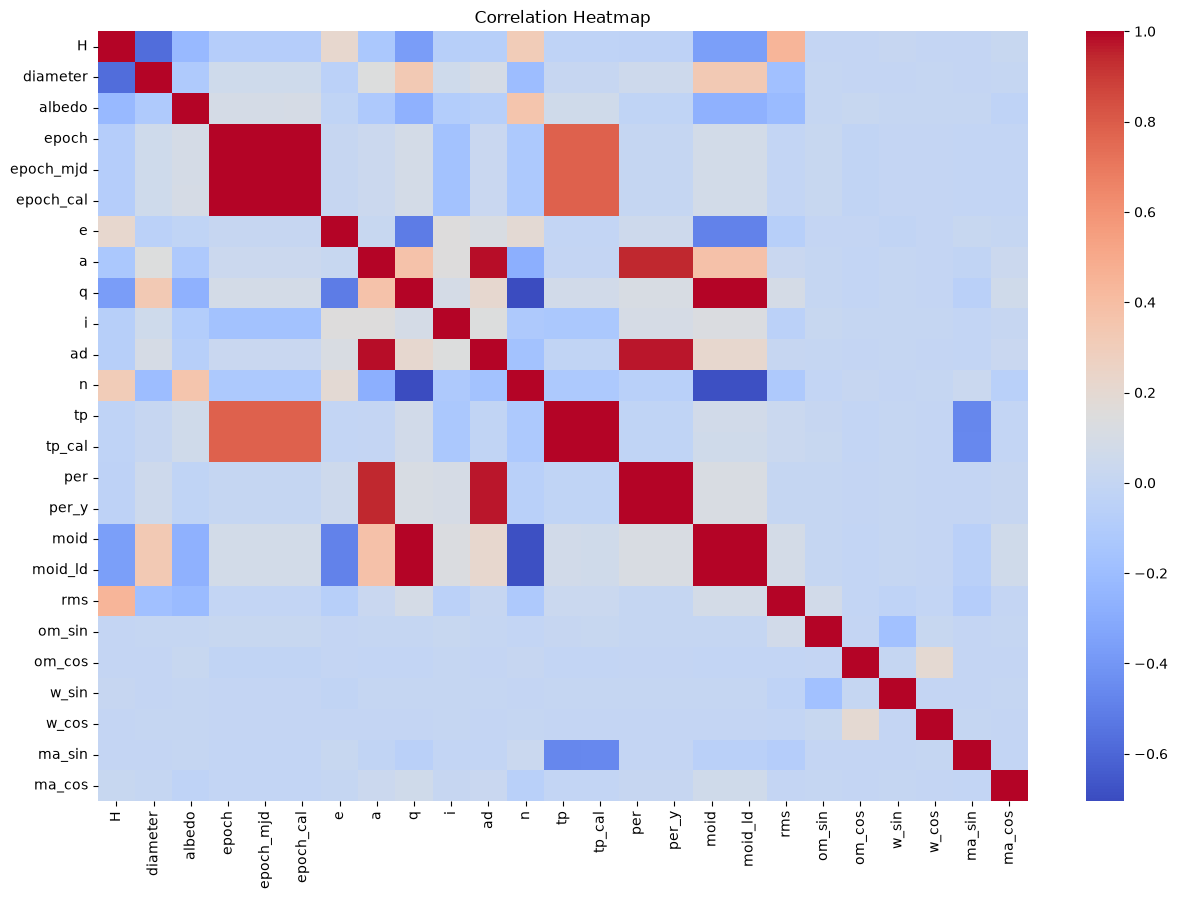

In [18]:
plt.figure(figsize=(15,10))

corr_matrix = regression_df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    corr_matrix,
    cmap='coolwarm'
)

plt.title(
    "Correlation Heatmap"
)

plt.show()
